## Pegasus Evaluation: Setup and Base Case

Section V of the paper, split over `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2), `2c_depth_and_load.ipynb`
(B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). The shared parameters and
helpers are in `pegasus/evaluation_setup.py`. `data_source` in the first code cell selects the data:

- **real**: the second testbed campaign in `statics/results_milos_v2/` (`pegasus/real_data.py`): the chains in `b1/`
  (one worker per service) and `b1-unthrottled/` (one to four workers per service), and every service alone in `benchmark/`.
- **synthetic**: generated service types (`pegasus/data.py`) and a simulated chain of queues (`pegasus/simulation.py`).

Experiments that the real data does not support (B.4, C.2) run on synthetic data (`skipped` in `pegasus/evaluation_setup.py`).

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table, time_table
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))

## A. Experimental Setup

- **Training (real):** every service is trained on its benchmark runs alone (one worker), drawn at random per seed; no
  run of an evaluated chain trains a model, so every chain is an unseen composition (B.2 also trains on the other chains
  of `b1/`). Training runs may be throttled for less than `TRAINING_THROTTLE_LIMIT` of their CPU periods.
- **Held-out runs (real):** the unthrottled runs of a chain in `b1/` and those of the same chain in `b1-unthrottled/` with
  at most three workers per service (`DEFAULT_CHAINS`, `combined_chain`, `unthrottled_runs`).
- **Model inputs:** the knobs of the application (`data_quality`, model size), neither the cores nor the number of
  workers (`NOT_CONFIGURATION`, `model_inputs`).
- **Synthetic:** the chain $s_1 \to s_2 \to s_3$ of generated service types; training and held-out configurations
  drawn uniformly at random; a seed draws the service types, the training data and the held-out configurations.
- **Ground truth:** the measured $(1-\varepsilon)$ end-to-end latency quantile of a held-out run, $\varepsilon$ = `alpha`,
  with a confidence interval (`coverage_check`).

## B. Coverage and Tightness of Service Bounds

**Methods** (`pegasus/evaluation.py`, `pegasus/bounds.py`, `pegasus/baselines.py`), all trained on each service alone:
- *Pegasus Node (ours):* martingale node bound per service at $\varepsilon/|S|$ for $|S|$ services, summed.
- *Pegasus SNC (ours):* network service curve of the chain at $\varepsilon$; evaluated in B.1 and B.3 only.
- *GP Sum, DNN Sum:* $(1-\varepsilon)$ quantile of the summed predicted execution times; DNN Sum in B.1 only.
- *GP Queue:* Allen-Cunneen G/G/c latency quantile per service, summed.
- *Quantile Union:* GP of the $(1-\varepsilon/|S|)$ latency quantile of each service monitored alone, summed.
- *Conformal:* Quantile Union with a correction factor calibrated on `n_calibration` training configurations.
- *Oracle (reference):* union bound over the measured latency quantiles of the services.

**Metrics.** *Tightness*: end-to-end latency ÷ measured quantile. *Coverage*: share of held-out configurations at which
a method is not below the lower edge of the confidence interval of the measured quantile. A method *holds* in a setting
if its coverage is at least `confidence` under every seed in `seeds`.

### B.1 Base Case: Every Chain of the Campaign

Real data only: every chain of the campaign as an unseen composition, `n_train` benchmark runs per service and seed.
Figure: `figures/tsc/b1_all_chains_benchmark`.

In [2]:
# B.1 on all chains: every chain of the second campaign as an unseen instance, every service trained on its benchmark (real data only)
if data_source != "real":
    print("B.1 on all chains skipped: real data only")
else:
    n_train = base_options["n_train"]   # training runs per service and seed (configure in pegasus/evaluation_setup.py)

    def compute():
        unseen = {}   # (chain, seed) -> held-out ground truth and the end-to-end latency (s) of every method per held-out run
        unseen_chains = chain_names   # the chains of the option that configure chose (chains)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            for chain in unseen_chains:
                for s in seeds:
                    data = load_chain_data("real", experiment=chain, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s],
                                           n_train=n_train, training_campaign=BENCHMARKS_V2)
                    models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence)
                    latencies, _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                   model_seed=seed + s, x_train_load=data.x_train_load)
                    unseen[(chain, s)] = SimpleNamespace(path=data.path, measured=data.measured, measured_low=data.measured_low,
                                                         latencies={name: latency for name, (_, latency) in latencies.items()})
        smallest_pool = min(len(unthrottled_pool(training_pool(service, campaign=BENCHMARKS_V2)))
                            for service in campaign_nodes(chain_campaign)["service"].unique())
        return dict(unseen=unseen, unseen_chains=unseen_chains, smallest_pool=smallest_pool)

    globals().update(cached("b1_all_chains", data_source, compute, inputs=dict(n_train=n_train)))
    chain_depth = {chain: len(unseen[(chain, seeds[0])].path) for chain in unseen_chains}
    held_out = [len(unseen[(chain, seeds[0])].measured) for chain in unseen_chains]
    print(f"{len(unseen_chains)} chains of {min(chain_depth.values())} to {max(chain_depth.values())} services, {min(held_out)} to {max(held_out)} "
          f"held-out runs per chain ({sum(held_out)} in all), {len(seeds)} seeds, {n_train} training runs per service and seed; "
          f"smallest unthrottled benchmark of a service: {smallest_pool} runs")

b1_all_chains: results loaded from statics/evaluation_cache/b1_all_chains_real+b1+b1u-max3_8f03761c7a8cd259.joblib
15 chains of 3 to 6 services, 86 to 125 held-out runs per chain (1666 in all), 3 seeds, 25 training runs per service and seed; smallest unthrottled benchmark of a service: 33 runs


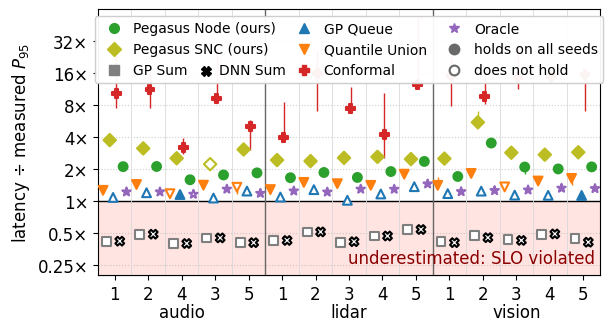

In [3]:
from pegasus.figures import FAILURE_COLOR, FAILURE_TEXT_COLOR, METHOD_STYLES, dodge_offsets, holds_handles, legend_entry_beside, legend_inside, method_handle, separated_order, paper_figure, paper_style, save_figure, tightness_label, tightness_tick


def unseen_holds(chain, name):
    # the method reaches the confidence level on the held-out runs of the chain under every seed
    return all(coverage(unseen[(chain, s)].latencies[name], unseen[(chain, s)].measured_low) >= confidence for s in seeds)


def unseen_tightness(chain, name):
    # median over the held-out runs of all seeds of latency / measured quantile (an infinite latency counts as infinitely loose)
    return np.median(np.concatenate([unseen[(chain, s)].latencies[name] / unseen[(chain, s)].measured for s in seeds]))


def seed_tightness(chain, name):
    # per seed the median over the held-out runs of latency / measured quantile; nan where that median is infinite
    medians = np.array([np.median(unseen[(chain, s)].latencies[name] / unseen[(chain, s)].measured) for s in seeds])
    return np.where(np.isfinite(medians), medians, np.nan)


if data_source == "real":
    unseen_names = list(unseen[(unseen_chains[0], seeds[0])].latencies)   # in the order of compare_methods
    application = lambda chain: chain.split("-")[1]
    applications = list(dict.fromkeys(application(chain) for chain in unseen_chains))   # in the order of the chains
    # the chains of an application by their number of services, so that the figure shows whether misses cluster in longer chains
    chain_order = sorted(unseen_chains, key=lambda chain: (applications.index(application(chain)), chain_depth[chain], chain))
    positions = np.arange(len(chain_order))
    seed_values = {name: np.array([seed_tightness(chain, name) for chain in chain_order]) for name in unseen_names}   # (chains, seeds)
    # median over the seeds, in which a seed without a finite value counts as infinitely loose, as in sweep_line
    typical_values = {name: np.median(np.where(np.isnan(values), np.inf, values), axis=1) for name, values in seed_values.items()}
    columns = dodge_offsets(len(unseen_names))   # one column per method within a chain
    with paper_style():
        fig, ax = paper_figure()
        # methods with similar values get columns far apart, so that their markers do not overlap: the distances of the
        # markers in pixels, a column being its share of the width of a chain and a doubling its share of TIGHTNESS_RANGE
        order = separated_order(typical_values, column_width=ax.bbox.width / len(chain_order) * (columns[1] - columns[0]),
                                doubling_height=ax.bbox.height / np.log2(TIGHTNESS_RANGE[1] / TIGHTNESS_RANGE[0]))
        offsets = dict(zip(order, columns))
        drawn = []   # (x, y_low, y_high) of every bar and dot, so that the legend can be placed where it hides none
        # below 1x the latency of a method is under the measured quantile: an SLO met with it is violated
        ax.axhspan(TIGHTNESS_RANGE[0], 1.0, color=FAILURE_COLOR, linewidth=0)
        ax.axhline(1.0, color="black", linewidth=1)
        # the chains are independent instances: no line connects them, every method is one dot per chain
        for name in unseen_names:
            color = METHOD_COLORS[name]
            values, typical = seed_values[name], typical_values[name]
            held = np.array([unseen_holds(chain, name) for chain in chain_order])
            shown, x = np.isfinite(typical), positions + offsets[name]
            ax.vlines(x[shown], np.nanmin(values[shown], axis=1), np.nanmax(values[shown], axis=1), color=color, linewidth=1)   # range over the seeds
            if name != "Conformal":   # the legend may cover parts of Conformal, so that the axis keeps TIGHTNESS_RANGE
                drawn += list(zip(x[shown], np.fmin(typical[shown], np.nanmin(values[shown], axis=1)), np.fmax(typical[shown], np.nanmax(values[shown], axis=1))))
            ax.scatter(x[shown], typical[shown], s=40, marker=METHOD_STYLES[name][0], linewidths=1.5, zorder=3, edgecolors=color,
                       facecolors=[color if h else "white" for h in held[shown]])
        for boundary in positions[1:] - 0.5:
            ax.axvline(boundary, color="0.85", linewidth=0.6)
        centers = []
        for k, app in enumerate(applications):
            chains_of_app = positions[[application(chain) == app for chain in chain_order]]
            if k > 0:
                ax.axvline(chains_of_app[0] - 0.5, color="0.4", linewidth=1)
            centers.append(chains_of_app.mean())
        # the application names below the instance numbers, in place of an axis label: the figure keeps the fixed layout of
        # every figure, and the top of the axes stays free for the legend
        names = ax.secondary_xaxis("bottom")
        names.set_xticks(centers, applications)
        names.tick_params(length=0, pad=20)
        ax.text(0.99, 0.03, "underestimated: SLO violated", transform=ax.transAxes, ha="right", va="bottom", color=FAILURE_TEXT_COLOR)
        ax.set_xticks(positions, [chain.split('-')[2] for chain in chain_order])
        ax.set_xlim(-0.5, len(chain_order) - 0.5)
        ax.set_yscale("log")
        ax.set_ylim(*TIGHTNESS_RANGE)
        ax.set_yticks(TIGHTNESS_TICKS, [tightness_tick(tick) for tick in TIGHTNESS_TICKS])
        ax.yaxis.set_minor_locator(plt.NullLocator())
        ax.set_ylabel(tightness_label(p_label))
        ax.grid(True, axis="y", linestyle=":", alpha=0.6)
        marker_handles, marker_labels = holds_handles()
        # DNN Sum sits in the row of GP Sum, in the space right of its short label, so that the legend keeps three rows
        legend_names = [name for name in unseen_names if name != "DNN Sum"]
        legend = legend_inside(ax, [method_handle(name, line=False) for name in legend_names] + marker_handles, legend_names + marker_labels, drawn,
                               max_doublings=0, ncol=3, fontsize=10, framealpha=0.95, columnspacing=1.0, handletextpad=0.4)
        legend_entry_beside(legend, "GP Sum", method_handle("DNN Sum", line=False), "DNN Sum")
        save_figure(fig, "b1_all_chains_benchmark")   # the name it had before, so that references to the file stay valid
        plt.show()

In [4]:
if data_source == "real":
    def pooled_tightness(name):
        # median over the held-out runs of all chains and seeds
        return np.median(np.concatenate([result.latencies[name] / result.measured for result in unseen.values()]))

    display(pd.DataFrame({f"chains held (of {len(unseen_chains)})": [sum(unseen_holds(chain, name) for chain in unseen_chains) for name in unseen_names],
                          "tightness (median)": [f"{pooled_tightness(name):.2f}×" for name in unseen_names]}, index=unseen_names))

,chains held (of 15),tightness (median)
Pegasus Node (ours),15,1.86×
Pegasus SNC (ours),14,2.66×
GP Sum,0,0.45×
DNN Sum,0,0.45×
GP Queue,2,1.14×
Quantile Union,12,1.45×
Conformal,15,9.97×
Oracle,14,1.26×
